# Chapitre 3 - Cours 1 : moindres carrés, géométrie et inférence

Ce premier notebook du chapitre 3 (*Linear Methods for Regression*, sections 3.1 et 3.2
du livre) pose les bases de la **régression linéaire** :

1. le modèle linéaire et le critère des moindres carrés ;
2. la solution explicite et son interprétation géométrique (projection orthogonale) ;
3. les propriétés statistiques de l'estimateur : variance, loi, tests $Z$ et $F$,
   intervalles de confiance ;
4. l'exemple du **cancer de la prostate** (tableaux 3.1 et 3.2 du livre) ;
5. le théorème de **Gauss–Markov** et le compromis biais–variance ;
6. la régression multiple vue comme une suite de régressions simples
   (**Gram–Schmidt**, algorithme 3.1) et la **décomposition QR** ;
7. le cas de plusieurs réponses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from scipy import stats
from esl import datasets
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)

## 1. Le modèle linéaire

On dispose d'un vecteur d'entrées $X = (X_1, \dots, X_p)^T$ et l'on veut prédire une
sortie réelle $Y$. Le **modèle de régression linéaire** suppose que la fonction de
régression $\mathbb{E}(Y \mid X)$ est linéaire en les paramètres (éq. (3.1) du livre) :

$$
f(X) = \beta_0 + \sum_{j=1}^{p} X_j \beta_j .
$$

Les $\beta_j$ sont des paramètres inconnus. Le modèle est « linéaire » **en les
paramètres**, pas forcément en les variables d'origine : les $X_j$ peuvent être

- des variables quantitatives brutes ou transformées ($\log$, racine carrée…) ;
- des puissances ou des fonctions de base ($X_2 = X_1^2$, $X_3 = X_1^3$ : régression
  polynomiale) ;
- un codage numérique d'une variable qualitative (variables indicatrices) ;
- des interactions ($X_3 = X_1 X_2$).

> **Remarque.** Toute cette souplesse fait la force du modèle linéaire : la seule chose
> qui compte pour la théorie qui suit est que $f$ dépende *linéairement* des $\beta_j$.

## 2. Le critère des moindres carrés

On observe $N$ couples $(x_i, y_i)$, avec $x_i = (x_{i1}, \dots, x_{ip})^T$. La méthode
des **moindres carrés** choisit $\beta = (\beta_0, \beta_1, \dots, \beta_p)^T$ qui
minimise la **somme des carrés des résidus** (éq. (3.2)) :

$$
\mathrm{RSS}(\beta) = \sum_{i=1}^{N} \bigl(y_i - f(x_i)\bigr)^2
  = \sum_{i=1}^{N} \Bigl(y_i - \beta_0 - \sum_{j=1}^{p} x_{ij}\beta_j\Bigr)^2 .
$$

Ce critère ne suppose **rien** sur la validité du modèle : il cherche simplement le
meilleur ajustement linéaire au sens des carrés.

**Écriture matricielle.** Notons $\mathbf{X}$ la matrice $N \times (p+1)$ dont la ligne
$i$ est $(1, x_{i1}, \dots, x_{ip})$ (la première colonne de uns porte $\beta_0$), et
$\mathbf{y} = (y_1, \dots, y_N)^T$. Alors le vecteur des résidus est
$\mathbf{y} - \mathbf{X}\beta$ et (éq. (3.3))

$$
\mathrm{RSS}(\beta) = (\mathbf{y} - \mathbf{X}\beta)^T(\mathbf{y} - \mathbf{X}\beta)
  = \lVert \mathbf{y} - \mathbf{X}\beta \rVert^2 .
$$

### 2.1 Résolution : les équations normales

**Rappel (dérivées matricielles).** Pour un vecteur constant $a$ et une matrice
symétrique $A$ : $\nabla_\beta (a^T\beta) = a$ et $\nabla_\beta(\beta^T A \beta) = 2A\beta$.

On développe le RSS :

$$
\mathrm{RSS}(\beta) = \mathbf{y}^T\mathbf{y} - 2\,\mathbf{y}^T\mathbf{X}\beta
  + \beta^T \mathbf{X}^T\mathbf{X}\beta ,
$$

car $\beta^T\mathbf{X}^T\mathbf{y}$ est un scalaire, égal à son transposé
$\mathbf{y}^T\mathbf{X}\beta$.

On dérive terme à terme (éq. (3.4)) :

$$
\frac{\partial \mathrm{RSS}}{\partial \beta} = -2\,\mathbf{X}^T(\mathbf{y} - \mathbf{X}\beta),
\qquad
\frac{\partial^2 \mathrm{RSS}}{\partial \beta\,\partial \beta^T} = 2\,\mathbf{X}^T\mathbf{X}.
$$

La hessienne $2\mathbf{X}^T\mathbf{X}$ est semi-définie positive
($v^T\mathbf{X}^T\mathbf{X}v = \lVert \mathbf{X}v\rVert^2 \ge 0$) : le RSS est une
fonction **convexe** de $\beta$, et tout point critique est un minimum global.

Si $\mathbf{X}$ est de **rang plein** $p+1$ (colonnes linéairement indépendantes), alors
$\mathbf{X}v = 0 \Rightarrow v = 0$, donc $\mathbf{X}^T\mathbf{X}$ est définie positive et
inversible. Annuler le gradient donne les **équations normales** (éq. (3.5)) :

$$
\mathbf{X}^T(\mathbf{y} - \mathbf{X}\beta) = 0
\quad\Longleftrightarrow\quad
\mathbf{X}^T\mathbf{X}\,\beta = \mathbf{X}^T\mathbf{y},
$$

dont l'unique solution est (éq. (3.6))

$$
\boxed{\hat\beta = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}.}
$$

### 2.2 Valeurs ajustées et matrice chapeau

Les valeurs ajustées aux points d'apprentissage sont (éq. (3.7))

$$
\hat{\mathbf{y}} = \mathbf{X}\hat\beta = \underbrace{\mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T}_{\mathbf{H}}\,\mathbf{y}.
$$

La matrice $\mathbf{H}$ s'appelle la **matrice chapeau** (« elle met un chapeau sur
$\mathbf{y}$ »).

**Propriété.** $\mathbf{H}$ est la matrice de la **projection orthogonale** sur
l'espace engendré par les colonnes de $\mathbf{X}$, noté $\mathrm{col}(\mathbf{X})$.

*Démonstration.*
- $\mathbf{H}^T = \mathbf{X}\bigl((\mathbf{X}^T\mathbf{X})^{-1}\bigr)^T\mathbf{X}^T = \mathbf{H}$
  car $\mathbf{X}^T\mathbf{X}$ est symétrique (donc son inverse aussi) : $\mathbf{H}$ est symétrique.
- $\mathbf{H}^2 = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}(\mathbf{X}^T\mathbf{X})(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T = \mathbf{H}$ :
  $\mathbf{H}$ est idempotente.
- Une matrice symétrique et idempotente est un projecteur orthogonal, sur son image ;
  ici $\mathrm{Im}(\mathbf{H}) \subset \mathrm{col}(\mathbf{X})$ et $\mathbf{H}\mathbf{X} = \mathbf{X}$,
  donc $\mathrm{Im}(\mathbf{H}) = \mathrm{col}(\mathbf{X})$. $\square$

> **Intuition.** Les équations normales $\mathbf{X}^T(\mathbf{y} - \hat{\mathbf{y}}) = 0$
> disent exactement que le résidu est **orthogonal à chaque colonne** de $\mathbf{X}$ :
> $\hat{\mathbf{y}}$ est le point de $\mathrm{col}(\mathbf{X})$ le plus proche de
> $\mathbf{y}$ (figure 3.2 du livre). La géométrie remplace le calcul différentiel.

Visualisons-le avec $N = 3$ observations et deux vecteurs d'entrée $\mathbf{x}_1, \mathbf{x}_2$
(sans constante, pour rester en dimension 3).

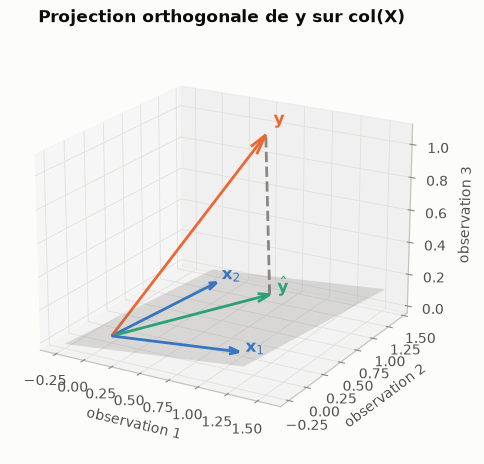

In [2]:
x1 = np.array([1.0, 0.2, 0.0])
x2 = np.array([0.3, 1.0, 0.1])
y3 = np.array([0.8, 0.9, 1.1])
X3 = np.column_stack([x1, x2])
H3 = X3 @ np.linalg.solve(X3.T @ X3, X3.T)
yhat3 = H3 @ y3

fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
s, t = np.meshgrid(np.linspace(-0.2, 1.2, 10), np.linspace(-0.2, 1.2, 10))
plane = s[..., None] * x1 + t[..., None] * x2
ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], color=GRAY, alpha=0.2)
for v, lab, col in [(x1, r"$\mathbf{x}_1$", BLUE), (x2, r"$\mathbf{x}_2$", BLUE),
                    (y3, r"$\mathbf{y}$", ORANGE), (yhat3, r"$\hat{\mathbf{y}}$", COLORS[2])]:
    ax.quiver(0, 0, 0, *v, color=col, arrow_length_ratio=0.08, linewidth=2)
    ax.text(*(1.05 * v), lab, color=col, fontsize=12)
ax.plot(*np.column_stack([yhat3, y3]), color=GRAY, linestyle="--")
ax.set_title("Projection orthogonale de y sur col(X)")
ax.set_xlabel("observation 1"); ax.set_ylabel("observation 2"); ax.set_zlabel("observation 3")
ax.view_init(elev=20, azim=-60)
plt.show()

Le segment pointillé $\mathbf{y} - \hat{\mathbf{y}}$ est perpendiculaire au plan gris
engendré par $\mathbf{x}_1$ et $\mathbf{x}_2$. Vérifions numériquement, sur un exemple
plus grand, les propriétés de $\mathbf{H}$ : symétrie, idempotence, trace et
orthogonalité des résidus.

In [3]:
rng = np.random.RandomState(0)
N, p = 50, 4
X = cr.add_intercept(rng.randn(N, p))
y = X @ np.array([1.0, 2.0, -1.0, 0.5, 0.0]) + rng.randn(N)
H = cr.hat_matrix(X)
res = y - H @ y
print("||H - H^T||          =", np.abs(H - H.T).max())
print("||H^2 - H||          =", np.abs(H @ H - H).max())
print("trace(H)             =", np.trace(H).round(10), "(= p + 1 =", p + 1, ")")
print("max |X^T (y - yhat)| =", np.abs(X.T @ res).max())

||H - H^T||          = 0.0
||H^2 - H||          = 5.551115123125783e-17
trace(H)             = 5.0 (= p + 1 = 5 )
max |X^T (y - yhat)| = 2.2537527399890678e-14


> **Remarque (rang déficient).** Si des colonnes de $\mathbf{X}$ sont liées (par ex.
> une variable codée deux fois), $\mathbf{X}^T\mathbf{X}$ n'est plus inversible et
> $\hat\beta$ n'est plus unique. En revanche $\hat{\mathbf{y}}$, projection de
> $\mathbf{y}$ sur $\mathrm{col}(\mathbf{X})$, reste parfaitement défini. Ce cas arrive
> notamment quand $p > N$ ; on y répond par la régularisation (cours 2).

## 3. Propriétés statistiques de $\hat\beta$

Jusqu'ici, aucune hypothèse probabiliste. Supposons maintenant que :
- les $x_i$ sont **fixés** (non aléatoires) ;
- les $y_i$ sont **non corrélés**, de **variance constante** $\sigma^2$.

Alors $\mathrm{Var}(\mathbf{y}) = \sigma^2 \mathbf{I}_N$.

**Variance de $\hat\beta$.** On écrit $\hat\beta = \mathbf{A}\mathbf{y}$ avec
$\mathbf{A} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T$. Pour un vecteur aléatoire
$\mathbf{y}$ et une matrice constante $\mathbf{A}$,
$\mathrm{Var}(\mathbf{A}\mathbf{y}) = \mathbf{A}\,\mathrm{Var}(\mathbf{y})\,\mathbf{A}^T$. D'où

$$
\mathrm{Var}(\hat\beta) = \sigma^2 (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}
  = (\mathbf{X}^T\mathbf{X})^{-1}\sigma^2 \qquad \text{(éq. (3.8))}.
$$

**Estimation de $\sigma^2$.** On utilise (éq. (3.8) du livre)

$$
\hat\sigma^2 = \frac{1}{N - p - 1}\sum_{i=1}^{N}(y_i - \hat y_i)^2 .
$$

*Pourquoi diviser par $N-p-1$ ?* Supposons de plus le modèle correct :
$\mathbf{y} = \mathbf{X}\beta + \varepsilon$ avec $\mathbb{E}\varepsilon = 0$. Le résidu vaut
$\mathbf{y} - \hat{\mathbf{y}} = (\mathbf{I} - \mathbf{H})\mathbf{y} = (\mathbf{I} - \mathbf{H})\varepsilon$
car $(\mathbf{I} - \mathbf{H})\mathbf{X} = 0$. Donc, comme $\mathbf{I} - \mathbf{H}$ est un
projecteur (symétrique, idempotent),

$$
\mathrm{RSS} = \varepsilon^T(\mathbf{I} - \mathbf{H})\varepsilon
  = \mathrm{tr}\bigl((\mathbf{I} - \mathbf{H})\varepsilon\varepsilon^T\bigr).
$$

Par linéarité de l'espérance et de la trace :

$$
\mathbb{E}(\mathrm{RSS}) = \mathrm{tr}\bigl((\mathbf{I} - \mathbf{H})\,\sigma^2\mathbf{I}\bigr)
  = \sigma^2\bigl(N - \mathrm{tr}\,\mathbf{H}\bigr) = \sigma^2 (N - p - 1),
$$

car $\mathrm{tr}\,\mathbf{H} = \mathrm{tr}\bigl((\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{X}\bigr)
= \mathrm{tr}\,\mathbf{I}_{p+1} = p+1$ (on a utilisé $\mathrm{tr}(AB) = \mathrm{tr}(BA)$).
Ainsi $\mathbb{E}\hat\sigma^2 = \sigma^2$ : $\hat\sigma^2$ est **sans biais**.

### 3.1 Le cas gaussien

Supposons enfin que le modèle linéaire est correct et que le bruit est gaussien
(éq. (3.9)) :

$$
Y = \beta_0 + \sum_{j=1}^p X_j\beta_j + \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0, \sigma^2).
$$

Alors $\hat\beta$, transformation linéaire d'un vecteur gaussien, est gaussien
(éq. (3.10)) :

$$
\hat\beta \sim \mathcal{N}\bigl(\beta,\ (\mathbf{X}^T\mathbf{X})^{-1}\sigma^2\bigr).
$$

**Rappel (loi du $\chi^2$).** Si $Z_1, \dots, Z_k$ sont i.i.d. $\mathcal{N}(0,1)$, la loi
de $Z_1^2 + \dots + Z_k^2$ est la loi du **khi-deux à $k$ degrés de liberté**, notée
$\chi^2_k$ ; son espérance vaut $k$.

En diagonalisant le projecteur $\mathbf{I} - \mathbf{H}$ (de rang $N-p-1$) dans une base
orthonormée, $\mathrm{RSS} = \varepsilon^T(\mathbf{I} - \mathbf{H})\varepsilon$ est la somme
des carrés de $N-p-1$ coordonnées gaussiennes indépendantes de variance $\sigma^2$. D'où
(éq. (3.11))

$$
(N - p - 1)\,\hat\sigma^2 \sim \sigma^2\,\chi^2_{N-p-1},
$$

et de plus $\hat\sigma^2$ est **indépendant** de $\hat\beta$ (ils dépendent de deux
projections orthogonales de $\varepsilon$, non corrélées donc indépendantes dans le cas gaussien).

Vérifions ces deux lois par simulation : on garde $\mathbf{X}$ fixe et l'on tire de
nombreux vecteurs de bruit.

In [4]:
rng = np.random.RandomState(0)
N, p, sigma = 30, 3, 1.5
Xs = cr.add_intercept(rng.randn(N, p))
beta_true = np.array([1.0, 2.0, 0.0, -1.0])
XtX_inv = np.linalg.inv(Xs.T @ Xs)
n_sim = 5000
B_hat = np.empty((n_sim, p + 1))
s2_hat = np.empty(n_sim)
for b in range(n_sim):
    yb = Xs @ beta_true + sigma * rng.randn(N)
    fit = cr.ols_fit(Xs[:, 1:], yb)
    B_hat[b], s2_hat[b] = fit["coef"], fit["sigma2"]
print("moyenne empirique de beta_hat :", B_hat.mean(0).round(3))
print("écarts-types empiriques       :", B_hat.std(0).round(3))
print("écarts-types théoriques       :", np.sqrt(np.diag(XtX_inv) * sigma**2).round(3))
print("E(sigma2_hat) empirique       :", s2_hat.mean().round(3), " (sigma^2 =", sigma**2, ")")

moyenne empirique de beta_hat : [ 1.008  2.    -0.002 -0.998]
écarts-types empiriques       : [0.288 0.247 0.28  0.301]
écarts-types théoriques       : [0.29  0.248 0.284 0.298]
E(sigma2_hat) empirique       : 2.237  (sigma^2 = 2.25 )


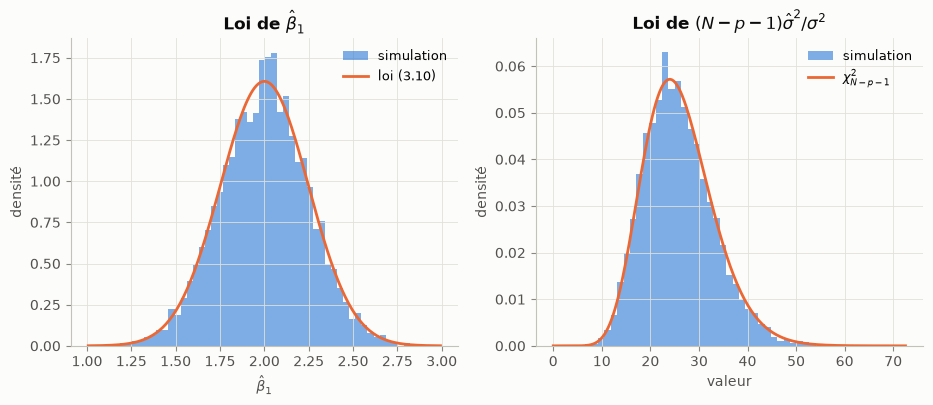

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sd1 = np.sqrt(XtX_inv[1, 1]) * sigma
grid = np.linspace(beta_true[1] - 4 * sd1, beta_true[1] + 4 * sd1, 200)
axes[0].hist(B_hat[:, 1], bins=50, density=True, color=BLUE, alpha=0.6, label="simulation")
axes[0].plot(grid, stats.norm.pdf(grid, beta_true[1], sd1), color=ORANGE, label="loi (3.10)")
axes[0].set_title(r"Loi de $\hat\beta_1$")
axes[0].set_xlabel(r"$\hat\beta_1$"); axes[0].set_ylabel("densité"); axes[0].legend()
q = (N - p - 1) * s2_hat / sigma**2
grid = np.linspace(0, q.max(), 200)
axes[1].hist(q, bins=50, density=True, color=BLUE, alpha=0.6, label="simulation")
axes[1].plot(grid, stats.chi2.pdf(grid, N - p - 1), color=ORANGE, label=r"$\chi^2_{N-p-1}$")
axes[1].set_title(r"Loi de $(N-p-1)\hat\sigma^2/\sigma^2$")
axes[1].set_xlabel("valeur"); axes[1].set_ylabel("densité"); axes[1].legend()
plt.show()

### 3.2 Tester un coefficient : le score $Z$

Pour tester l'hypothèse $H_0 : \beta_j = 0$, on forme le **score $Z$** (éq. (3.12)) :

$$
z_j = \frac{\hat\beta_j}{\hat\sigma\sqrt{v_j}},
$$

où $v_j$ est le $j$-ième élément diagonal de $(\mathbf{X}^T\mathbf{X})^{-1}$ ; le
dénominateur $\hat\sigma\sqrt{v_j}$ est l'**erreur standard** de $\hat\beta_j$.